# DeepBeak: Bird Species Identification from Audio

**ARTE 4110U — Deep Learning Architecture and Algorithms | Group 18**

This notebook compares two models that classify bird species from short audio recordings:

1. **SmallCNN:** a convolutional neural network trained from scratch (baseline).
2. **ResNet18:** an ImageNet-pretrained ResNet18 fine-tuned on log-mel spectrograms.

The main experiment compares classification performance on clean and artificially noisy test audio. A smaller secondary analysis checks whether species mistakes are still within the correct **genus**.

Run the cells from top to bottom. The code, data preparation, training, evaluation, and inference are kept together here so the experiment is easy to follow. This notebook belongs in the GitHub repository under `notebooks/`.

## 1. Experiment setup

- Dataset: BirdCLEF 2023, downloaded through the team's Kaggle account.
- Prediction target: `primary_label` (bird **species**).
- Subset: 20 well-represented species, selected from genera with multiple eligible species. This keeps the subset taxonomically related without making species selection random.
- Split: 70% training, 15% validation, 15% test, using a fixed seed.
- Input: 5-second mono audio converted to a 96-bin log-mel spectrogram.
- Metrics: accuracy, macro-F1, and macro recall.
- Noise experiment: clean audio and synthetic noise at 10, 5, and 0 dB SNR.

**Taxonomy note:** BirdCLEF's `primary_label` is a species label, not a subspecies label. The genus analysis therefore measures related-species confusions. It does not measure true subspecies recognition.

## 2. Install dependencies

PyTorch and Torchvision are normally available in Kaggle or Colab runtimes. The remaining libraries are installed here.

In [26]:
%pip -q install kagglehub librosa soundfile scikit-learn matplotlib tqdm


## 3. Imports and configuration

Change the values in this cell to run a smaller or longer experiment. Start with the defaults, then adjust only if your runtime is too slow.

In [1]:
from pathlib import Path
import json
import random
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import kagglehub

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from tqdm.auto import tqdm

SEED = 4110
N_SPECIES = 20
MIN_RECORDINGS_PER_SPECIES = 40
MAX_RECORDINGS_PER_SPECIES = 60
MAX_SPECIES_PER_GENUS = 4

SAMPLE_RATE = 32000
CLIP_SECONDS = 5
N_MELS = 96
N_FFT = 1024
HOP_LENGTH = 320

BATCH_SIZE = 16
MAX_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 3
NUM_WORKERS = 0  # Keep notebook data loading simple and avoid cache-write conflicts.

CNN_LEARNING_RATE = 1e-3
RESNET_LEARNING_RATE = 1e-4
TRAIN_WITH_NOISE = True
TEST_NOISE_LEVELS_DB = [10, 5, 0]

DEVICE = torch.device('cpu')
OUTPUT_DIR = Path.cwd() / 'outputs' / 'deepbeak'
CACHE_DIR = OUTPUT_DIR / 'audio_cache'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


print('Device:', DEVICE)



Device: cpu


## 4. Download BirdCLEF 2023 from Kaggle

This uses your Kaggle account through KaggleHub. You must have accepted the BirdCLEF 2023 competition rules on Kaggle. No Google Drive is used.

In [2]:
COMPETITION = 'birdclef-2023'

# Reuse the Kaggle login available in this runtime, or sign in if needed.
try:
    print('Kaggle account:', kagglehub.whoami().get('username', 'logged in'))
except Exception:
    kagglehub.login()
    print('Kaggle account:', kagglehub.whoami().get('username', 'logged in'))

download_dir = Path(kagglehub.competition_download(COMPETITION))
print('Downloaded to:', download_dir)

metadata_matches = list(download_dir.rglob('train_metadata.csv'))
if not metadata_matches:
    raise FileNotFoundError('train_metadata.csv was not found in the Kaggle download.')
METADATA_PATH = metadata_matches[0]
DATA_ROOT = METADATA_PATH.parent

# Find the audio folder.
audio_matches = [p for p in DATA_ROOT.rglob('train_audio') if p.is_dir()]


if not audio_matches:
    raise FileNotFoundError('Could not find train_audio in the Kaggle download.')
AUDIO_DIR = audio_matches[0]
print('Metadata:', METADATA_PATH)
print('Audio folder:', AUDIO_DIR)


Kaggle credentials successfully validated.
Kaggle account: jonathanleaper
Downloaded to: /home/jon/.cache/kagglehub/competitions/birdclef-2023
Metadata: /home/jon/.cache/kagglehub/competitions/birdclef-2023/train_metadata.csv
Audio folder: /home/jon/.cache/kagglehub/competitions/birdclef-2023/train_audio


## 5. Inspect metadata and find the audio files

`primary_label` is the classification target. `scientific_name` is used only to identify each species' genus for selecting related species and for the secondary genus analysis.

In [3]:
metadata = pd.read_csv(METADATA_PATH)
required_columns = {'filename', 'primary_label', 'scientific_name'}
missing_columns = required_columns - set(metadata.columns)
if missing_columns:
    raise ValueError(f'Metadata is missing columns: {missing_columns}')

metadata = metadata.dropna(subset=['filename', 'primary_label', 'scientific_name']).copy()
metadata['filename'] = metadata['filename'].astype(str)
metadata['primary_label'] = metadata['primary_label'].astype(str)
metadata['genus'] = metadata['scientific_name'].astype(str).str.split().str[0]

# Resolve each metadata filename to the downloaded audio file.
def find_audio_file(filename):
    relative_path = Path(filename)
    candidates = [AUDIO_DIR / relative_path, DATA_ROOT / relative_path]
    if relative_path.parts and relative_path.parts[0] == 'train_audio':
        candidates.append(DATA_ROOT / relative_path)
    for candidate in candidates:
        if candidate.is_file():
            return str(candidate.resolve())
    return None

metadata['audio_path'] = metadata['filename'].map(find_audio_file)
metadata = metadata.dropna(subset=['audio_path']).drop_duplicates('filename').reset_index(drop=True)

print('Usable recordings:', len(metadata))
print('Available species:', metadata['primary_label'].nunique())
print('Metadata columns:', metadata.columns.tolist())
if 'license' in metadata.columns:
    display(metadata['license'].value_counts(dropna=False).to_frame('recordings'))

metadata.head()


Usable recordings: 16941
Available species: 264
Metadata columns: ['primary_label', 'secondary_labels', 'type', 'latitude', 'longitude', 'scientific_name', 'common_name', 'author', 'license', 'rating', 'url', 'filename', 'genus', 'audio_path']


,recordings
license,
Creative Commons Attribution-NonCommercial-ShareAlike 4.0,15512
Creative Commons Attribution-NonCommercial-ShareAlike 3.0,1330
Creative Commons Attribution-ShareAlike 4.0,94
Creative Commons Attribution-ShareAlike 3.0,5


,primary_label,secondary_labels,type,latitude,longitude,scientific_name,common_name,author,license,rating,url,filename,genus,audio_path
0,abethr1,[],['song'],4.3906,38.2788,Turdus tephronotus,African Bare-eyed Thrush,Rolf A. de By,Creative Commons Attribution-NonCommercial-Sha...,4.0,https://www.xeno-canto.org/128013,abethr1/XC128013.ogg,Turdus,/home/jon/.cache/kagglehub/competitions/birdcl...
1,abethr1,[],['call'],-2.9524,38.2921,Turdus tephronotus,African Bare-eyed Thrush,James Bradley,Creative Commons Attribution-NonCommercial-Sha...,3.5,https://www.xeno-canto.org/363501,abethr1/XC363501.ogg,Turdus,/home/jon/.cache/kagglehub/competitions/birdcl...
2,abethr1,[],['song'],-2.9524,38.2921,Turdus tephronotus,African Bare-eyed Thrush,James Bradley,Creative Commons Attribution-NonCommercial-Sha...,3.5,https://www.xeno-canto.org/363502,abethr1/XC363502.ogg,Turdus,/home/jon/.cache/kagglehub/competitions/birdcl...
3,abethr1,[],['song'],-2.9524,38.2921,Turdus tephronotus,African Bare-eyed Thrush,James Bradley,Creative Commons Attribution-NonCommercial-Sha...,5.0,https://www.xeno-canto.org/363503,abethr1/XC363503.ogg,Turdus,/home/jon/.cache/kagglehub/competitions/birdcl...
4,abethr1,[],"['call', 'song']",-2.9524,38.2921,Turdus tephronotus,African Bare-eyed Thrush,James Bradley,Creative Commons Attribution-NonCommercial-Sha...,4.5,https://www.xeno-canto.org/363504,abethr1/XC363504.ogg,Turdus,/home/jon/.cache/kagglehub/competitions/birdcl...


## 6. Select a related-species subset

This selects species with at least 30 recordings, then prioritizes genera that contain several eligible species. Up to four species are selected from each genus until 20 species have been chosen. The selection is based on taxonomy and recording counts, not a random list of species.

The random seed is used only when capping the number of recordings per selected species.

In [4]:
species_table = (
    metadata.groupby('primary_label')
    .agg(
        recordings=('filename', 'count'),
        genus=('genus', 'first'),
        scientific_name=('scientific_name', 'first'),
        common_name=('common_name', 'first') if 'common_name' in metadata.columns else ('scientific_name', 'first'),
    )
    .reset_index()
)
eligible = species_table[species_table['recordings'] >= MIN_RECORDINGS_PER_SPECIES].copy()

genus_summary = (
    eligible.groupby('genus')
    .agg(species_count=('primary_label', 'count'), total_recordings=('recordings', 'sum'))
    .query('species_count >= 2')
    .sort_values(['species_count', 'total_recordings'], ascending=False)
)

selected_species = []
selected_genera = []
for genus in genus_summary.index:
    genus_species = eligible[eligible['genus'] == genus].sort_values('recordings', ascending=False)
    chosen = genus_species['primary_label'].head(MAX_SPECIES_PER_GENUS).tolist()
    selected_species.extend(chosen)
    selected_genera.append(genus)
    if len(selected_species) >= N_SPECIES:
        break

selected_species = selected_species[:N_SPECIES]
if len(selected_species) < N_SPECIES:
    raise ValueError(
        f'Only {len(selected_species)} species were found. Lower MIN_RECORDINGS_PER_SPECIES '
        'or increase MAX_SPECIES_PER_GENUS and rerun this cell.'
    )

# Keep a similar number of files per species so common classes do not dominate training.
selected_frames = []
for species_code in selected_species:
    group = metadata[metadata['primary_label'] == species_code]
    n = min(len(group), MAX_RECORDINGS_PER_SPECIES)
    selected_frames.append(group.sample(n=n, random_state=SEED))

selected_metadata = pd.concat(selected_frames, ignore_index=True)
class_codes = selected_species
class_to_idx = {code: i for i, code in enumerate(class_codes)}
selected_metadata['label'] = selected_metadata['primary_label'].map(class_to_idx)

species_info = species_table.set_index('primary_label')
class_names = [str(species_info.loc[code, 'common_name']) for code in class_codes]
class_genera = [str(species_info.loc[code, 'genus']) for code in class_codes]

subset_summary = pd.DataFrame({
    'species_code': class_codes,
    'species_name': class_names,
    'genus': class_genera,
    'recordings': [int((selected_metadata['primary_label'] == code).sum()) for code in class_codes],
})
display(subset_summary)
print('Selected genera:', selected_genera)
print('Total selected recordings:', len(selected_metadata))
subset_summary.to_csv(OUTPUT_DIR / 'selected_species.csv', index=False)


,species_code,species_name,genus,recordings
0,eubeat1,European Bee-eater,Merops,60
1,bcbeat1,Blue-cheeked Bee-eater,Merops,60
2,wfbeat1,White-fronted Bee-eater,Merops,48
3,rindov,Ring-necked Dove,Streptopelia,60
4,laudov1,Laughing Dove,Streptopelia,60
5,reedov1,Red-eyed Dove,Streptopelia,60
6,afecuc1,African Emerald Cuckoo,Chrysococcyx,60
7,didcuc1,Dideric Cuckoo,Chrysococcyx,60
8,klacuc1,Klaas's Cuckoo,Chrysococcyx,56
9,eaywag1,Western Yellow Wagtail,Motacilla,60


Selected genera: ['Merops', 'Streptopelia', 'Chrysococcyx', 'Motacilla', 'Phylloscopus', 'Camaroptera', 'Cossypha', 'Cecropis', 'Cisticola']
Total selected recordings: 1144


## 7. Create train, validation, and test splits

The same fixed-seed split is used for both models. Every audio filename is assigned to one split only.

In [5]:
train_parts, val_parts, test_parts = [], [], []
for i, species_code in enumerate(class_codes):
    group = selected_metadata[selected_metadata['primary_label'] == species_code]
    group = group.sample(frac=1, random_state=SEED + i).reset_index(drop=True)
    n_train = int(len(group) * 0.70)
    n_val = int(len(group) * 0.15)
    train_parts.append(group.iloc[:n_train])
    val_parts.append(group.iloc[n_train:n_train + n_val])
    test_parts.append(group.iloc[n_train + n_val:])

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

assert set(train_df['filename']).isdisjoint(val_df['filename'])
assert set(train_df['filename']).isdisjoint(test_df['filename'])
assert set(val_df['filename']).isdisjoint(test_df['filename'])

for split_name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    frame.to_csv(OUTPUT_DIR / f'{split_name}_split.csv', index=False)
    print(f'{split_name:10s}: {len(frame):4d} recordings')

split_counts = pd.DataFrame({
    'train': train_df['primary_label'].value_counts(),
    'validation': val_df['primary_label'].value_counts(),
    'test': test_df['primary_label'].value_counts(),
}).fillna(0).astype(int)
display(split_counts)


train     :  800 recordings
validation:  171 recordings
test      :  173 recordings


,train,validation,test
primary_label,,,
afecuc1,42,9,9
afpwag1,42,9,9
bcbeat1,42,9,9
brwwar1,28,6,6
carcha1,42,9,9
didcuc1,42,9,9
eaywag1,42,9,9
eubeat1,42,9,9
gnbcam2,42,9,9


## 8. Audio preprocessing and PyTorch dataset

Each recording is converted to mono 32 kHz audio, cropped or padded to five seconds, and transformed into a log-mel spectrogram. Training clips use a random crop and optional noise augmentation; validation and test clips use a consistent centre crop.

In [6]:
def load_waveform(audio_path, species_code):
    # Cache the decoded audio so librosa does not have to reopen it every epoch.
    cache_path = CACHE_DIR / f'{species_code}_{Path(audio_path).stem}.npy'
    if cache_path.exists():
        return np.load(cache_path)
    waveform, _ = librosa.load(audio_path, sr=SAMPLE_RATE, mono=True)
    waveform = waveform.astype(np.float32)
    np.save(cache_path, waveform)
    return waveform


def crop_audio(waveform, training=False):
    target_length = SAMPLE_RATE * CLIP_SECONDS
    if len(waveform) < target_length:
        return np.pad(waveform, (0, target_length - len(waveform))).astype(np.float32)
    if training:
        start = np.random.randint(0, len(waveform) - target_length + 1)
    else:
        start = (len(waveform) - target_length) // 2
    return waveform[start:start + target_length].astype(np.float32)


def add_noise(waveform, snr_db, rng):
    signal_power = np.mean(waveform ** 2) + 1e-12
    noise = rng.normal(size=len(waveform)).astype(np.float32)
    noise_power = np.mean(noise ** 2) + 1e-12
    desired_noise_power = signal_power / (10 ** (snr_db / 10))
    noise = noise * np.sqrt(desired_noise_power / noise_power)
    return waveform + noise


def to_log_mel(waveform):
    mel = librosa.feature.melspectrogram(
        y=waveform, sr=SAMPLE_RATE, n_fft=N_FFT,
        hop_length=HOP_LENGTH, n_mels=N_MELS
    )
    log_mel = librosa.power_to_db(mel, ref=np.max)
    log_mel = (log_mel - log_mel.mean()) / (log_mel.std() + 1e-6)
    return torch.tensor(log_mel, dtype=torch.float32).unsqueeze(0)


class BirdDataset(Dataset):
    def __init__(self, frame, training=False, snr_db=None):
        self.frame = frame.reset_index(drop=True)
        self.training = training
        self.snr_db = snr_db

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        waveform = load_waveform(row['audio_path'], row['primary_label'])
        waveform = crop_audio(waveform, training=self.training)

        if self.training and TRAIN_WITH_NOISE:
            rng = np.random.default_rng(SEED + index + random.randint(0, 1_000_000))
            waveform = add_noise(waveform, rng.uniform(5, 20), rng)
        elif self.snr_db is not None:
            # The same test item gets the same noise for both models.
            rng = np.random.default_rng(SEED + index + int(self.snr_db * 100))
            waveform = add_noise(waveform, self.snr_db, rng)

        return to_log_mel(waveform), torch.tensor(int(row['label']), dtype=torch.long)


train_dataset = BirdDataset(train_df, training=True)
val_dataset = BirdDataset(val_df)
test_dataset = BirdDataset(test_df)
print('Dataset sizes:', len(train_dataset), len(val_dataset), len(test_dataset))


Dataset sizes: 800 171 173


## 9. Inspect a few spectrograms

These are the model inputs. The vertical axis is mel frequency and the horizontal axis is time.

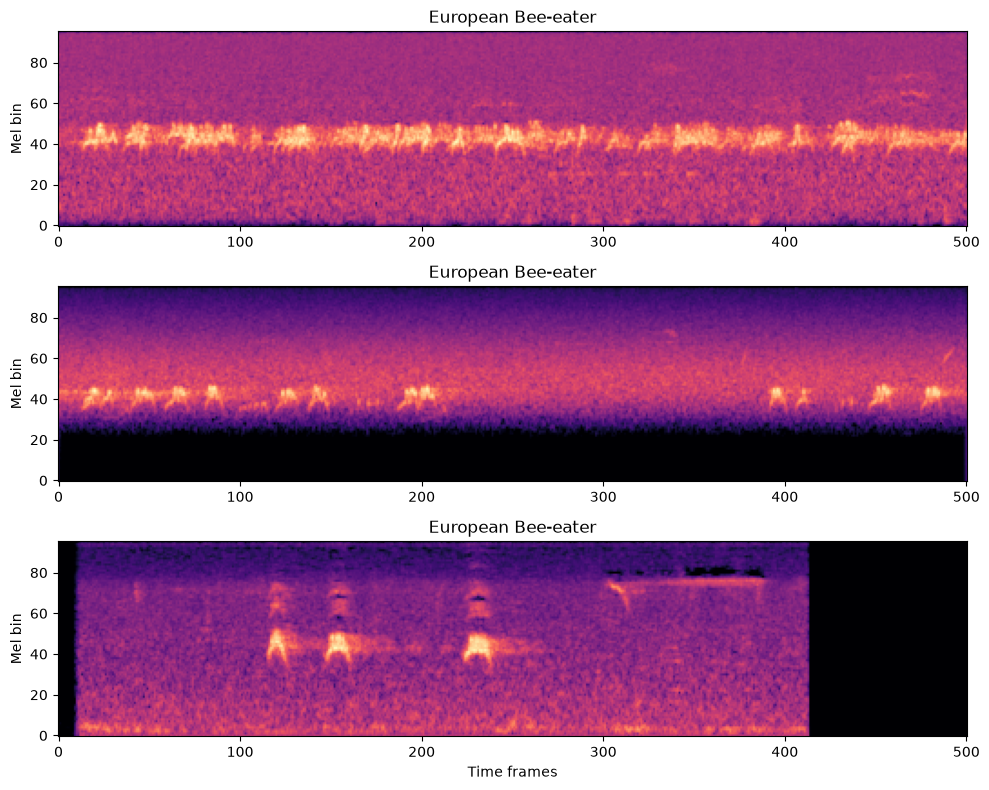

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8))
for i, ax in enumerate(axes):
    spectrogram, label = val_dataset[i]
    ax.imshow(spectrogram.squeeze(0).numpy(), origin='lower', aspect='auto', cmap='magma')
    ax.set_title(class_names[int(label)])
    ax.set_ylabel('Mel bin')
axes[-1].set_xlabel('Time frames')
plt.tight_layout()
plt.show()


## 10. Define the two models

The baseline learns all convolutional filters from scratch. ResNet18 starts with ImageNet weights; the final classification layer is replaced with one output per selected bird species. The one-channel spectrogram is repeated into three channels for ResNet18.

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 96, 3, padding=1), nn.BatchNorm2d(96), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.1),
            nn.Linear(96, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


class ResNet18Audio(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = models.resnet18(weights=ResNet18_Weights.DEFAULT)
        self.network.fc = nn.Linear(self.network.fc.in_features, num_classes)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = x.repeat(1, 3, 1, 1)
        x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)
        x = (x - self.mean) / self.std
        return self.network(x)


cnn = SmallCNN(N_SPECIES).to(DEVICE)
print('SmallCNN parameters:', sum(p.numel() for p in cnn.parameters()))
del cnn
print('ResNet18 will use pretrained ImageNet weights.')


SmallCNN parameters: 81044
ResNet18 will use pretrained ImageNet weights.


## 11. Data loaders and training functions

Both models use the same training and validation recordings. The best checkpoint is chosen using validation macro-F1. Training and validation loss are plotted as a learning curve.

In [9]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


def get_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
    }


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    y_true, y_pred = [], []

    for x, y in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(y)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    return total_loss / len(loader.dataset), get_metrics(y_true, y_pred)


def train_model(model, model_name, learning_rate):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    checkpoint_path = OUTPUT_DIR / f'{model_name}_best.pt'
    history = []
    best_f1 = -1
    patience_count = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_metrics = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_metrics = run_epoch(model, val_loader, criterion)
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'val_loss': val_loss,
            'train_macro_f1': train_metrics['macro_f1'],
            'val_macro_f1': val_metrics['macro_f1'],
            'val_accuracy': val_metrics['accuracy'],
        })
        print(f"Epoch {epoch}: train loss={train_loss:.4f}, val loss={val_loss:.4f}, "
              f"val macro-F1={val_metrics['macro_f1']:.4f}")

        if val_metrics['macro_f1'] > best_f1:
            best_f1 = val_metrics['macro_f1']
            patience_count = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_count += 1
            if patience_count >= EARLY_STOPPING_PATIENCE:
                print('Early stopping.')
                break

    # Reload the best validation checkpoint before final test evaluation.
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f'{model_name}_history.csv', index=False)

    plt.figure(figsize=(7, 4))
    plt.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Training loss')
    plt.plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Cross-entropy loss')
    plt.title(f'{model_name}: learning curve')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{model_name}_learning_curve.png', dpi=160)
    plt.show()
    return model, history_df


## 12. Train the baseline SmallCNN

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 1: train loss=2.9890, val loss=2.9641, val macro-F1=0.0344


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 2: train loss=2.8779, val loss=2.9595, val macro-F1=0.0284


... (20 outputs left out)

Epoch 9: train loss=2.4932, val loss=2.7459, val macro-F1=0.0701


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 10: train loss=2.4429, val loss=3.1947, val macro-F1=0.0418
Early stopping.


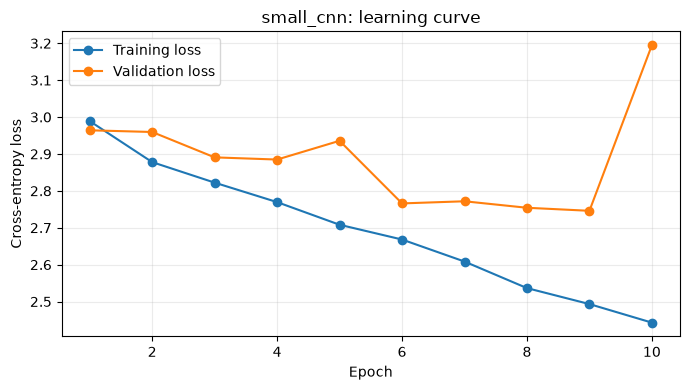

In [10]:
baseline_model, baseline_history = train_model(
    SmallCNN(N_SPECIES), 'small_cnn', CNN_LEARNING_RATE
)


## 13. Train the pretrained ResNet18

The first run may download the pretrained ImageNet weights. Enable internet access in the notebook runtime if the download is blocked.

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 1: train loss=2.7228, val loss=2.5803, val macro-F1=0.1801


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 2: train loss=1.9585, val loss=2.1342, val macro-F1=0.3782


... (32 outputs left out)

Epoch 13: train loss=0.4202, val loss=1.5081, val macro-F1=0.5738


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Epoch 14: train loss=0.3651, val loss=1.3478, val macro-F1=0.6363
Early stopping.


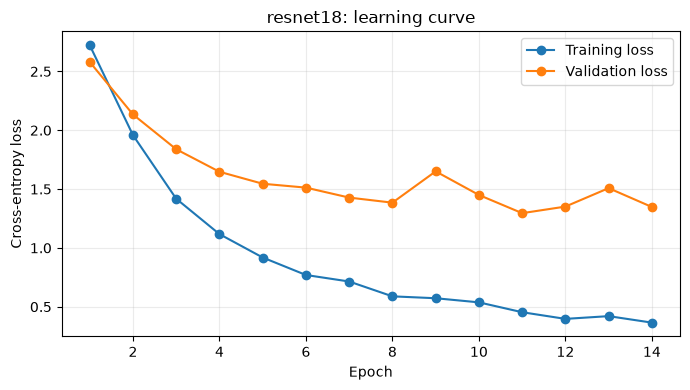

In [11]:
resnet_model, resnet_history = train_model(
    ResNet18Audio(N_SPECIES), 'resnet18', RESNET_LEARNING_RATE
)


## 14. Compare validation performance

Validation data is used to select checkpoints. The test set is kept for the final comparison.

In [12]:
def best_val_row(history):
    return history.loc[history['val_macro_f1'].idxmax()]

validation_comparison = pd.DataFrame([
    {
        'model': 'SmallCNN baseline',
        'best_epoch': int(best_val_row(baseline_history)['epoch']),
        'val_macro_f1': best_val_row(baseline_history)['val_macro_f1'],
        'val_accuracy': best_val_row(baseline_history)['val_accuracy'],
    },
    {
        'model': 'ResNet18 pretrained',
        'best_epoch': int(best_val_row(resnet_history)['epoch']),
        'val_macro_f1': best_val_row(resnet_history)['val_macro_f1'],
        'val_accuracy': best_val_row(resnet_history)['val_accuracy'],
    },
])
display(validation_comparison)
validation_comparison.to_csv(OUTPUT_DIR / 'validation_comparison.csv', index=False)


,model,best_epoch,val_macro_f1,val_accuracy
0,SmallCNN baseline,7,0.140604,0.192982
1,ResNet18 pretrained,11,0.643634,0.660819


## 15. Evaluate on clean and noisy test audio

The same test recordings and noise levels are used for both models. Noise is added to the waveform before the log-mel transformation.

In [13]:
def evaluate_model(model, dataset):
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in tqdm(loader, leave=False):
            logits = model(x.to(DEVICE))
            y_true.extend(y.tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    metrics = get_metrics(y_true, y_pred)
    metrics['y_true'] = y_true
    metrics['y_pred'] = y_pred
    metrics['confusion_matrix'] = confusion_matrix(y_true, y_pred, labels=list(range(N_SPECIES)))
    metrics['per_class_recall'] = recall_score(
        y_true, y_pred, labels=list(range(N_SPECIES)), average=None, zero_division=0
    )
    return metrics


models_to_test = {
    'SmallCNN baseline': baseline_model,
    'ResNet18 pretrained': resnet_model,
}
test_results = {}
summary_rows = []

for model_name, model in models_to_test.items():
    for snr_db in [None] + TEST_NOISE_LEVELS_DB:
        condition = 'Clean' if snr_db is None else f'{snr_db} dB SNR'
        test_data = BirdDataset(test_df, snr_db=snr_db)
        result = evaluate_model(model, test_data)
        test_results[(model_name, condition)] = result
        summary_rows.append({
            'model': model_name,
            'condition': condition,
            'accuracy': result['accuracy'],
            'macro_f1': result['macro_f1'],
            'macro_recall': result['macro_recall'],
        })
        print(model_name, condition, result['accuracy'], result['macro_f1'])

test_comparison = pd.DataFrame(summary_rows)
display(test_comparison)
test_comparison.to_csv(OUTPUT_DIR / 'test_comparison.csv', index=False)


  0%|          | 0/11 [00:00<?, ?it/s]

SmallCNN baseline Clean 0.13872832369942195 0.09767943477407894


  0%|          | 0/11 [00:00<?, ?it/s]

SmallCNN baseline 10 dB SNR 0.20809248554913296 0.1872024261330394


  0%|          | 0/11 [00:00<?, ?it/s]

SmallCNN baseline 5 dB SNR 0.10982658959537572 0.0869017443273736


... (7 outputs left out)

ResNet18 pretrained 5 dB SNR 0.6705202312138728 0.6591160340824229


  0%|          | 0/11 [00:00<?, ?it/s]

ResNet18 pretrained 0 dB SNR 0.6473988439306358 0.6379306692059081


,model,condition,accuracy,macro_f1,macro_recall
0,SmallCNN baseline,Clean,0.138728,0.097679,0.133333
1,SmallCNN baseline,10 dB SNR,0.208092,0.187202,0.200000
2,SmallCNN baseline,5 dB SNR,0.109827,0.086902,0.105556
3,SmallCNN baseline,0 dB SNR,0.075145,0.035015,0.072222
4,ResNet18 pretrained,Clean,0.658960,0.658184,0.663889
5,ResNet18 pretrained,10 dB SNR,0.705202,0.694497,0.702083
6,ResNet18 pretrained,5 dB SNR,0.670520,0.659116,0.665972
7,ResNet18 pretrained,0 dB SNR,0.647399,0.637931,0.641667


## 16. Plot the noise comparison

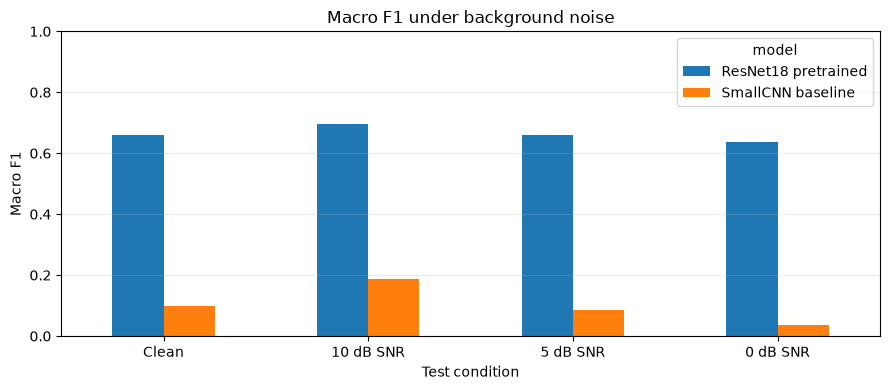

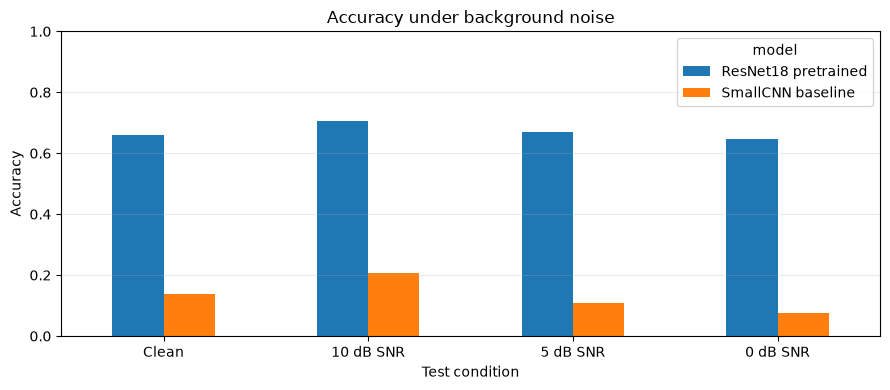

In [14]:
for metric in ['macro_f1', 'accuracy']:
    pivot = test_comparison.pivot(index='condition', columns='model', values=metric)
    pivot = pivot.reindex(['Clean'] + [f'{snr} dB SNR' for snr in TEST_NOISE_LEVELS_DB])
    ax = pivot.plot(kind='bar', figsize=(9, 4), ylim=(0, 1), rot=0)
    ax.set_ylabel(metric.replace('_', ' ').title())
    ax.set_xlabel('Test condition')
    ax.set_title(f'{metric.replace("_", " ").title()} under background noise')
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'noise_{metric}.png', dpi=160)
    plt.show()


## 17. Confusion matrices and per-species recall

Use the clean test results to see which species are commonly confused and whether the models perform equally well across classes.

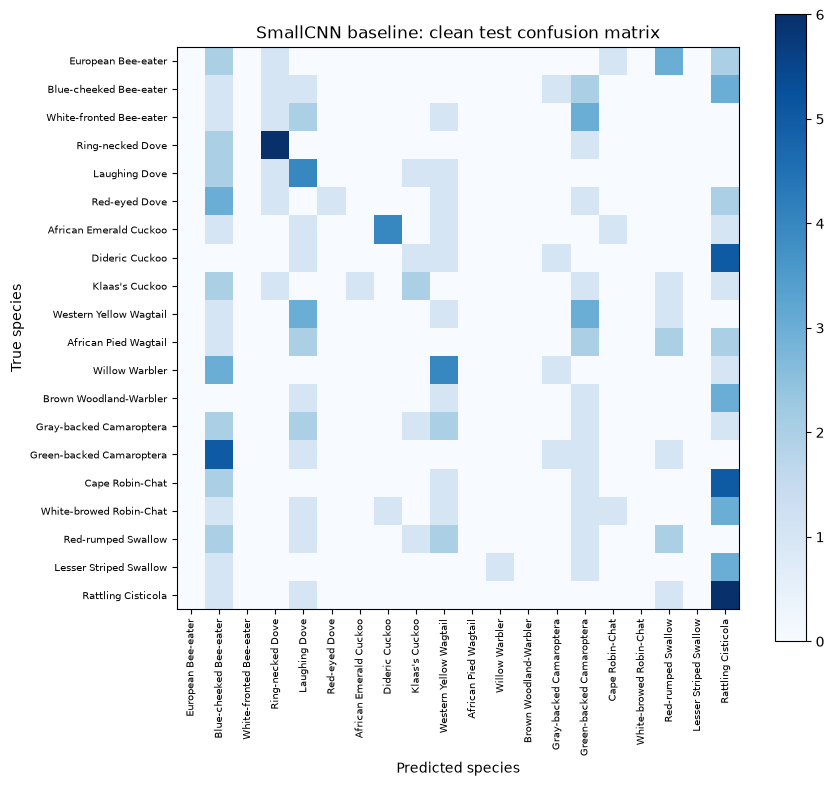

,species,genus,recall
0,European Bee-eater,Merops,0.000000
2,White-fronted Bee-eater,Merops,0.000000
6,African Emerald Cuckoo,Chrysococcyx,0.000000
7,Dideric Cuckoo,Chrysococcyx,0.000000
12,Brown Woodland-Warbler,Phylloscopus,0.000000
13,Gray-backed Camaroptera,Camaroptera,0.000000
10,African Pied Wagtail,Motacilla,0.000000
11,Willow Warbler,Phylloscopus,0.000000
15,Cape Robin-Chat,Cossypha,0.000000
16,White-browed Robin-Chat,Cossypha,0.000000


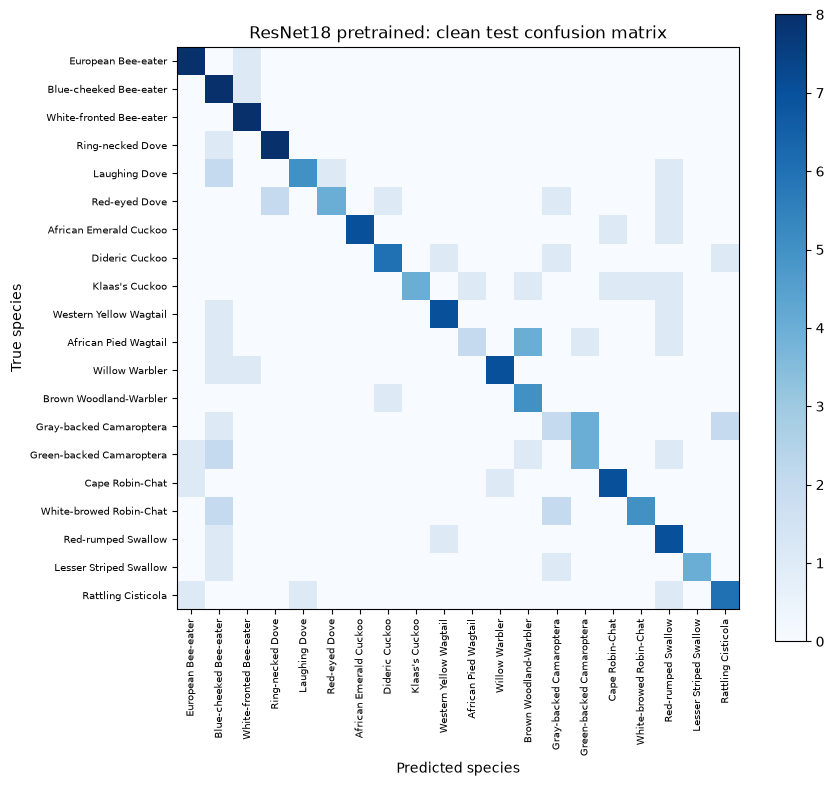

,species,genus,recall
13,Gray-backed Camaroptera,Camaroptera,0.222222
10,African Pied Wagtail,Motacilla,0.222222
5,Red-eyed Dove,Streptopelia,0.444444
14,Green-backed Camaroptera,Camaroptera,0.444444
8,Klaas's Cuckoo,Chrysococcyx,0.444444
4,Laughing Dove,Streptopelia,0.555556
16,White-browed Robin-Chat,Cossypha,0.555556
7,Dideric Cuckoo,Chrysococcyx,0.666667
18,Lesser Striped Swallow,Cecropis,0.666667
19,Rattling Cisticola,Cisticola,0.666667


In [15]:
for model_name in models_to_test:
    result = test_results[(model_name, 'Clean')]
    fig, ax = plt.subplots(figsize=(9, 8))
    image = ax.imshow(result['confusion_matrix'], cmap='Blues')
    ax.set_title(f'{model_name}: clean test confusion matrix')
    ax.set_xlabel('Predicted species')
    ax.set_ylabel('True species')
    ax.set_xticks(range(N_SPECIES), class_names, rotation=90, fontsize=7)
    ax.set_yticks(range(N_SPECIES), class_names, fontsize=7)
    fig.colorbar(image, ax=ax)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{model_name.split()[0].lower()}_confusion_matrix.png', dpi=160)
    plt.show()

    recall_table = pd.DataFrame({
        'species': class_names,
        'genus': class_genera,
        'recall': result['per_class_recall'],
    }).sort_values('recall')
    display(recall_table)
    recall_table.to_csv(OUTPUT_DIR / f'{model_name.split()[0].lower()}_per_species_recall.csv', index=False)


## 18. Secondary analysis: errors within the same genus

Species classification is the main task. This extra analysis checks whether an incorrect species prediction is still from the same genus. It is a related-species analysis, **not subspecies classification**.

In [16]:
within_genus_rows = []
genus_by_index = np.array(class_genera)
for model_name in models_to_test:
    result = test_results[(model_name, 'Clean')]
    y_true = np.array(result['y_true'])
    y_pred = np.array(result['y_pred'])
    true_genus = genus_by_index[y_true]
    predicted_genus = genus_by_index[y_pred]
    species_correct = y_true == y_pred
    genus_correct = true_genus == predicted_genus
    species_errors = ~species_correct
    within_genus_errors = species_errors & genus_correct
    within_genus_rows.append({
        'model': model_name,
        'species_accuracy': float(species_correct.mean()),
        'genus_accuracy': float(genus_correct.mean()),
        'species_errors': int(species_errors.sum()),
        'errors_within_same_genus': int(within_genus_errors.sum()),
        'within_genus_share_of_species_errors': float(within_genus_errors.sum() / max(species_errors.sum(), 1)),
    })

within_genus_comparison = pd.DataFrame(within_genus_rows)
display(within_genus_comparison)
within_genus_comparison.to_csv(OUTPUT_DIR / 'within_genus_comparison.csv', index=False)


,model,species_accuracy,genus_accuracy,species_errors,errors_within_same_genus,within_genus_share_of_species_errors
0,SmallCNN baseline,0.138728,0.219653,149,14,0.093960
1,ResNet18 pretrained,0.658960,0.710983,59,9,0.152542


## 19. Try a new recording

Use a local audio file path from the downloaded dataset or upload a short recording into the notebook runtime.

In [17]:
def predict_audio(audio_path, model=resnet_model, top_k=5):
    waveform, _ = librosa.load(str(audio_path), sr=SAMPLE_RATE, mono=True)
    waveform = crop_audio(waveform, training=False)
    x = to_log_mel(waveform).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    top_indices = np.argsort(probabilities)[::-1][:top_k]
    return pd.DataFrame([
        {'rank': rank + 1, 'species': class_names[index], 'confidence': float(probabilities[index])}
        for rank, index in enumerate(top_indices)
    ])

# Example:
# predict_audio(test_df.iloc[0]['audio_path'])


## 20. Save the experiment configuration

The small result files and configuration should be committed to GitHub when useful. Keep the BirdCLEF audio, cache files, credentials, and model checkpoints out of the repository.

In [18]:
experiment_config = {
    'project': 'DeepBeak',
    'course': 'ARTE 4110U',
    'group': 18,
    'seed': SEED,
    'selected_species': class_codes,
    'selected_genera': selected_genera,
    'recordings_per_species_cap': MAX_RECORDINGS_PER_SPECIES,
    'split': {'train': 0.70, 'validation': 0.15, 'test': 0.15},
    'sample_rate': SAMPLE_RATE,
    'clip_seconds': CLIP_SECONDS,
    'n_mels': N_MELS,
    'max_epochs': MAX_EPOCHS,
    'batch_size': BATCH_SIZE,
    'models': ['SmallCNN trained from scratch', 'ImageNet-pretrained ResNet18'],
    'noise_levels_db': TEST_NOISE_LEVELS_DB,
    'device': str(DEVICE),
}
(OUTPUT_DIR / 'experiment_config.json').write_text(json.dumps(experiment_config, indent=2))
print('Saved experiment files to:', OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print('-', path.name)


Saved experiment files to: /home/jon/Projects/deepFinal/ARTE-4110U-Final-Project-Group-18/outputs/deepbeak
- experiment_config.json
- noise_accuracy.png
- noise_macro_f1.png
- resnet18_best.pt
- resnet18_confusion_matrix.png
- resnet18_history.csv
- resnet18_learning_curve.png
- resnet18_per_species_recall.csv
- selected_species.csv
- small_cnn_best.pt
- small_cnn_history.csv
- small_cnn_learning_curve.png
- smallcnn_confusion_matrix.png
- smallcnn_per_species_recall.csv
- test_comparison.csv
- test_split.csv
- train_split.csv
- validation_comparison.csv
- validation_split.csv
- within_genus_comparison.csv
